In [ ]:
#(Farag Abdelkadir) | NUMBER: 
#(1197)

import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss
import warnings
warnings.filterwarnings('ignore')

train_df = pd.read_csv('training.csv.gz')
test_df = pd.read_csv('testing.csv.gz')

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
display(train_df.head())
train_df.info()

Train shape: (425719, 29)
Test shape: (213977, 28)


,shot_id,outcome,season_id,off_team_id,def_team_id,shooter_id,closestdef_id,num_contesters,contester1_id,contester2_id,...,shottype,distance,locationx,locationy,three,dribblesbefore,shotclock,closestdefdist,closestdefapproach,shooterspeed
0,2,False,fe055,b25360,374b0a,8f2113635e,c84ddbc387,0,NaN,NaN,...,jumper,24.794001,-21.91,14.87,True,1,20.57,11.332678,"{20.0470047638,18.8207810677,16.568961947,13.8...",2.386667
1,3,True,2676a,82f2ae,1f6160,c41ce2b6ec,e6e50816d4,1,e6e50816d4,NaN,...,jumper,16.458630,-34.91,-14.97,False,2,6.64,2.969714,"{5.5902504416,5.3995647973,4.9714786533,4.0232...",4.470777
2,4,True,2676a,1f6160,9dd789,90c89ca866,5318b35f44,2,5318b35f44,6484b807e1,...,layup,6.355289,-40.31,-6.19,False,2,14.31,2.556345,"{1.7779201332,0.4825971405,0.2961418579,2.1266...",8.414604
3,7,True,2676a,7831ab,188c02,fcf6c715f3,6a403360ae,0,NaN,NaN,...,dunk,2.310087,-39.61,-0.87,False,0,20.65,3.689255,"{8.6818258448,7.0713860028,5.388970217,3.55443...",12.971724
4,9,True,2676a,82f2ae,791f8d,7ff33cf9e0,fb6bcd9f22,1,fb6bcd9f22,NaN,...,jumper,24.959908,-32.32,23.11,True,0,18.87,9.199810,"{20.1202485074,17.8820244939,14.6324707415,11....",0.041667


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425719 entries, 0 to 425718
Data columns (total 29 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   shot_id             425719 non-null  int64  
 1   outcome             425719 non-null  bool   
 2   season_id           425719 non-null  object 
 3   off_team_id         425719 non-null  object 
 4   def_team_id         425719 non-null  object 
 5   shooter_id          425719 non-null  object 
 6   closestdef_id       425719 non-null  object 
 7   num_contesters      425719 non-null  int64  
 8   contester1_id       379712 non-null  object 
 9   contester2_id       69703 non-null   object 
 10  contester3_id       4066 non-null    object 
 11  contester4_id       37 non-null      object 
 12  distcont1           379712 non-null  float64
 13  distcont2           69703 non-null   float64
 14  distcont3           4066 non-null    float64
 15  distcont4           37 non-null   

In [15]:
print("Missing values in train:\n", train_df.isnull().sum())

Missing values in train:
 shot_id                    0
outcome                    0
season_id                  0
off_team_id                0
def_team_id                0
shooter_id                 0
closestdef_id              0
num_contesters             0
contester1_id          46007
contester2_id         356016
contester3_id         421653
contester4_id         425682
distcont1              46007
distcont2             356016
distcont3             421653
distcont4             425682
contested                  0
month                      0
gamestate                  0
shottype                   0
distance                   0
locationx                  0
locationy                  0
three                      0
dribblesbefore             0
shotclock                  0
closestdefdist             0
closestdefapproach         0
shooterspeed               0
dtype: int64


In [16]:
categorical_cols = train_df.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    print(f"{col}: {train_df[col].nunique()} unique values")

season_id: 2 unique values
off_team_id: 30 unique values
def_team_id: 30 unique values
shooter_id: 767 unique values
closestdef_id: 764 unique values
contester1_id: 763 unique values
contester2_id: 738 unique values
contester3_id: 576 unique values
contester4_id: 36 unique values
month: 7 unique values
gamestate: 3 unique values
shottype: 7 unique values
closestdefapproach: 425718 unique values


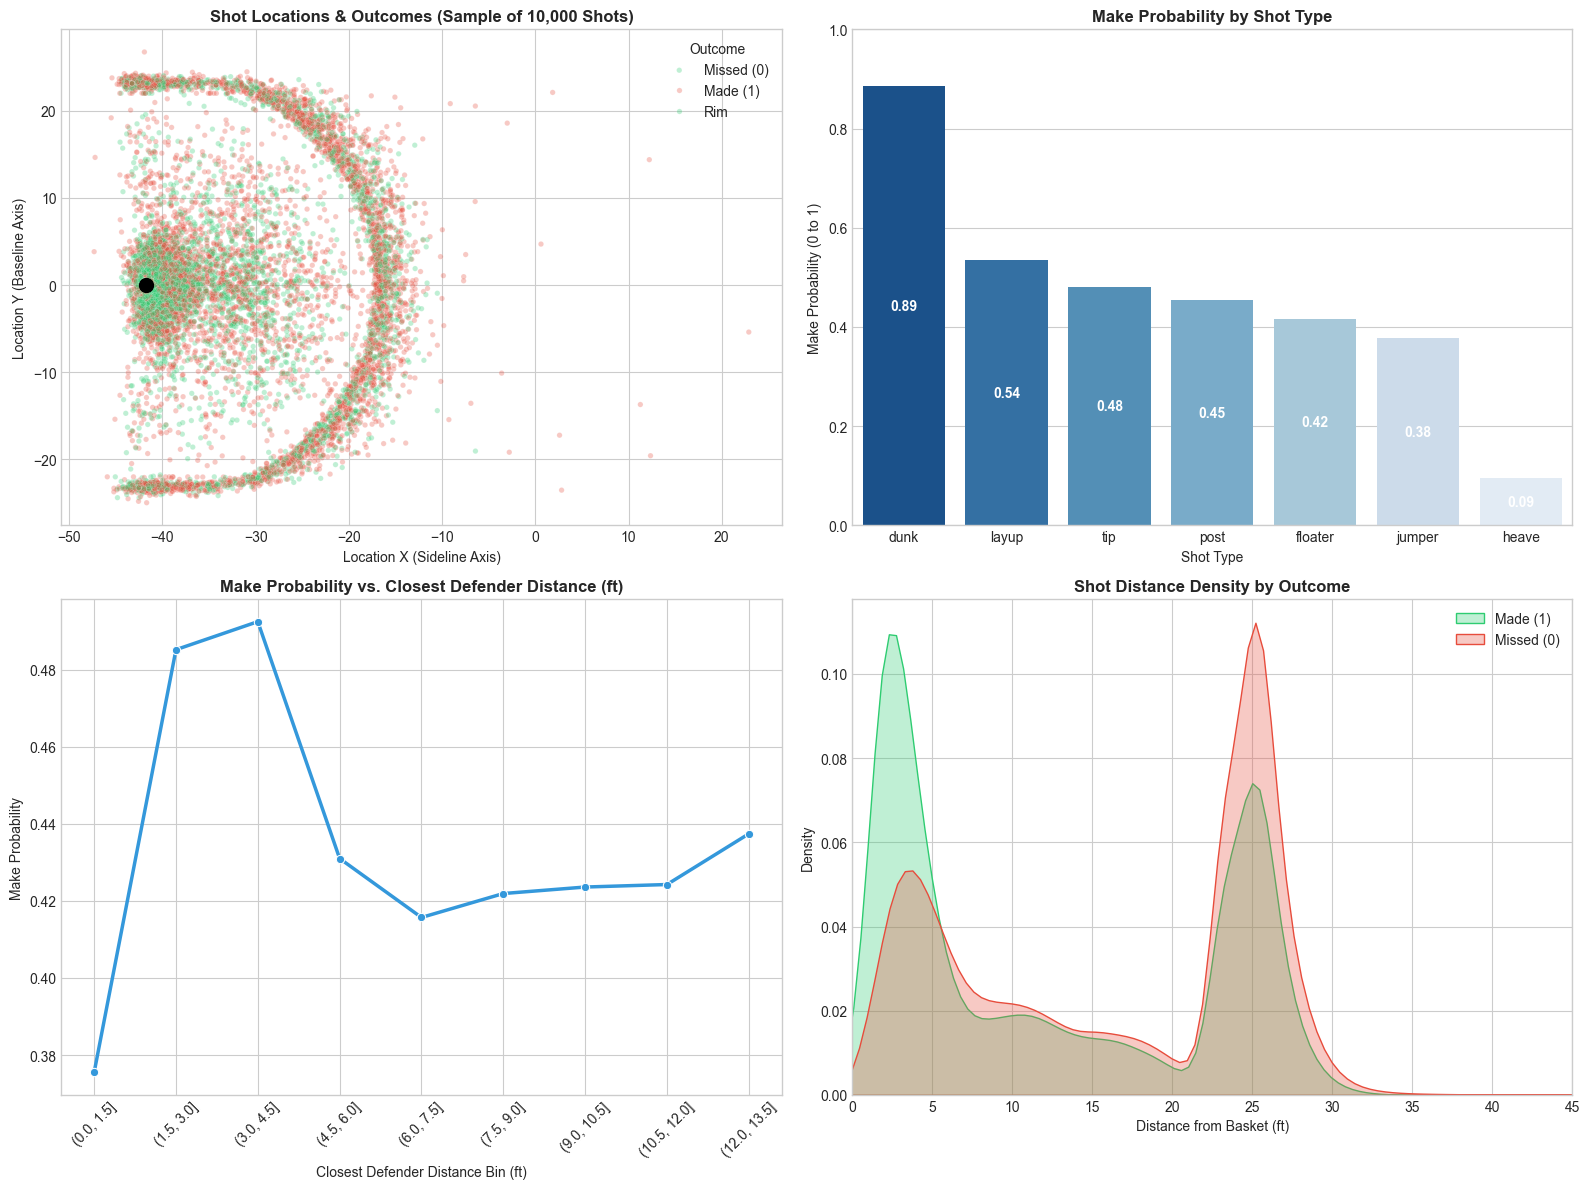

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns


train = pd.read_csv('training.csv.gz')


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

ax1 = axes[0, 0]
sns.scatterplot(
    data=train.sample(10000, random_state=42), 
    x='locationx', 
    y='locationy', 
    hue='outcome', 
    palette={0: '#e74c3c', 1: '#2ecc71'}, 
    alpha=0.3, 
    s=15,
    ax=ax1
)
ax1.plot(-41.75, 0, 'ko', markersize=10, label='Rim Center') # Rim center coordinates
ax1.set_title('Shot Locations & Outcomes (Sample of 10,000 Shots)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Location X (Sideline Axis)')
ax1.set_ylabel('Location Y (Baseline Axis)')
ax1.legend(title='Outcome', labels=['Missed (0)', 'Made (1)', 'Rim'])

ax2 = axes[0, 1]
shot_type_eff = train.groupby('shottype')['outcome'].agg(['mean', 'count']).reset_index()
shot_type_eff = shot_type_eff.sort_values(by='mean', ascending=False)

sns.barplot(data=shot_type_eff, x='shottype', y='mean', ax=ax2, palette='Blues_r')
ax2.set_title('Make Probability by Shot Type', fontsize=12, fontweight='bold')
ax2.set_xlabel('Shot Type')
ax2.set_ylabel('Make Probability (0 to 1)')
ax2.set_ylim(0, 1)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold')

ax3 = axes[1, 0]
train['def_dist_bin'] = pd.cut(train['closestdefdist'], bins=np.arange(0, 15, 1.5))
def_eff = train.groupby('def_dist_bin', observed=False)['outcome'].mean().reset_index()

sns.lineplot(data=def_eff, x=def_eff.index, y='outcome', marker='o', color='#3498db', linewidth=2.5, ax=ax3)
ax3.set_xticks(range(len(def_eff)))
ax3.set_xticklabels([str(b) for b in def_eff['def_dist_bin']], rotation=45)
ax3.set_title('Make Probability vs. Closest Defender Distance (ft)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Closest Defender Distance Bin (ft)')
ax3.set_ylabel('Make Probability')

ax4 = axes[1, 1]
sns.kdeplot(data=train[train['outcome'] == 1]['distance'], label='Made (1)', color='#2ecc71', fill=True, alpha=0.3, ax=ax4)
sns.kdeplot(data=train[train['outcome'] == 0]['distance'], label='Missed (0)', color='#e74c3c', fill=True, alpha=0.3, ax=ax4)
ax4.set_title('Shot Distance Density by Outcome', fontsize=12, fontweight='bold')
ax4.set_xlabel('Distance from Basket (ft)')
ax4.set_ylabel('Density')
ax4.set_xlim(0, 45)
ax4.legend()

plt.tight_layout()
plt.savefig('eda_visualizations.png', dpi=300)
plt.show()

In [18]:
train = pd.read_csv('training.csv.gz')
test = pd.read_csv('testing.csv.gz')

In [24]:
def engineer_features(df):
    df = df.copy()
    
    rim_x, rim_y = -41.75, 0.0
    df['dist_to_rim_calc'] = np.sqrt((df['locationx'] - rim_x)**2 + (df['locationy'] - rim_y)**2)
    
    df['shot_angle'] = np.degrees(np.arctan2(df['locationy'] - rim_y, df['locationx'] - rim_x))
    
    def parse_approach_diff(val):
        try:
            if isinstance(val, str):
                vals = [float(x) for x in val.strip('[]').split(',')]
            else:
                vals = list(val)
            return vals[0] - vals[-1] # Distance 1s before minus 0.25s before
        except:
            return np.nan

    if 'closestdefapproach' in df.columns:
        df['def_closing_speed'] = df['closestdefapproach'].apply(parse_approach_diff)

    df['defender_ratio'] = df['closestdefdist'] / (df['distance'] + 1e-5)
    
    return df

train_fe = engineer_features(train)
test_fe = engineer_features(test)

In [25]:
train_fe

,shot_id,outcome,season_id,off_team_id,def_team_id,shooter_id,closestdef_id,num_contesters,contester1_id,contester2_id,...,three,dribblesbefore,shotclock,closestdefdist,closestdefapproach,shooterspeed,dist_to_rim_calc,shot_angle,def_closing_speed,defender_ratio
0,2,False,fe055,b25360,374b0a,8f2113635e,c84ddbc387,0,NaN,NaN,...,True,1,20.57,11.332678,"{20.0470047638,18.8207810677,16.568961947,13.8...",2.386667,24.794001,36.851411,NaN,0.457073
1,3,True,2676a,82f2ae,1f6160,c41ce2b6ec,e6e50816d4,1,e6e50816d4,NaN,...,False,2,6.64,2.969714,"{5.5902504416,5.3995647973,4.9714786533,4.0232...",4.470777,16.458630,-65.443684,NaN,0.180435
2,4,True,2676a,1f6160,9dd789,90c89ca866,5318b35f44,2,5318b35f44,6484b807e1,...,False,2,14.31,2.556345,"{1.7779201332,0.4825971405,0.2961418579,2.1266...",8.414604,6.355289,-76.904023,NaN,0.402238
3,7,True,2676a,7831ab,188c02,fcf6c715f3,6a403360ae,0,NaN,NaN,...,False,0,20.65,3.689255,"{8.6818258448,7.0713860028,5.388970217,3.55443...",12.971724,2.310087,-22.123810,NaN,1.597013
4,9,True,2676a,82f2ae,791f8d,7ff33cf9e0,fb6bcd9f22,1,fb6bcd9f22,NaN,...,True,0,18.87,9.199810,"{20.1202485074,17.8820244939,14.6324707415,11....",0.041667,24.959908,67.802160,NaN,0.368583
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
425714,639687,False,2676a,916954,9dd789,74c85c3dcc,8295ed1026,1,8295ed1026,NaN,...,True,0,16.95,5.253808,"{16.6432719139,14.1015779259,10.3722128786,7.8...",0.515388,28.422957,-41.248504,NaN,0.184844
425715,639688,True,2676a,916954,019212,146d71e125,b6ea0b917a,1,08582a2100,NaN,...,False,2,5.78,3.612035,"{13.9989606757,10.3932333756,7.0709334603,4.06...",13.582055,2.848877,-63.974611,NaN,1.267876
425716,639691,False,2676a,188c02,4ce3a0,97a00d4a69,77b660404e,2,77b660404e,c67fbd2738,...,False,2,2.90,3.749733,"{8.4255088867,7.0956676923,6.5467320092,4.4009...",3.294830,17.238776,1.828322,NaN,0.217517
425717,639694,True,2676a,5ab44a,28049c,dd3de3b8aa,9cf745cb7a,1,9cf745cb7a,NaN,...,True,0,8.16,6.198847,"{18.3141284259,15.3885216964,12.4377248723,9.5...",0.971825,25.596252,-50.850765,NaN,0.242178


In [26]:
test_fe

,shot_id,season_id,off_team_id,def_team_id,shooter_id,closestdef_id,num_contesters,contester1_id,contester2_id,contester3_id,...,three,dribblesbefore,shotclock,closestdefdist,closestdefapproach,shooterspeed,dist_to_rim_calc,shot_angle,def_closing_speed,defender_ratio
0,1,d7a2d,e801cc,16981c,45a36b40c8,c97e433df4,1,c97e433df4,NaN,NaN,...,True,0,17.72,5.004448,"{9.2888373869,9.0637299165,8.2469691402,7.2762...",1.634056,25.689301,47.334733,NaN,0.194807
1,5,d7a2d,b25360,5ab44a,2cb9af8508,9f12db4242,1,9f12db4242,NaN,NaN,...,False,0,18.51,2.259380,"{6.9195447827,5.5875933997,3.106927743,2.06526...",15.212956,4.002812,-64.075098,NaN,0.564447
2,6,d7a2d,82f2ae,28049c,90b1c72e19,b25b22c4c2,0,NaN,NaN,NaN,...,True,0,13.75,15.123822,"{23.2157963465,22.4655692116,19.4195597272,17....",0.671855,23.003254,93.514186,NaN,0.657464
3,8,d7a2d,16981c,c3d95c,c40278f00f,eab37a8ca6,1,eab37a8ca6,NaN,NaN,...,False,0,6.05,4.490167,"{13.3664729828,10.673153236,8.4145706961,6.036...",4.335937,9.287723,-38.881398,NaN,0.483451
4,10,d7a2d,08555d,28049c,46a7a7ad66,0e1a8257a8,1,0e1a8257a8,NaN,NaN,...,True,0,6.35,7.831328,"{18.7330857042,16.1505572659,11.8374194823,9.8...",1.536591,25.464332,30.724511,NaN,0.307541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
213972,639689,d7a2d,efeae9,342d3f,4498318275,b4e570b5f5,1,b4e570b5f5,NaN,NaN,...,False,2,11.62,3.924411,"{6.5634518357,5.7576123524,5.3421812025,4.7205...",0.689706,19.993324,-4.561352,NaN,0.196286
213973,639690,d7a2d,08555d,916954,80db449b61,146d71e125,1,065b5273fd,NaN,NaN,...,True,0,0.00,6.422227,"{12.7110424435,11.664098765,9.5747845929,7.873...",2.243819,24.696042,-2.065282,NaN,0.260051
213974,639692,d7a2d,019212,29c72d,b9963ca1e6,26417591c3,1,26417591c3,NaN,NaN,...,True,0,5.01,10.196200,"{17.2380335305,16.3731731805,14.6130934439,12....",1.041667,25.369115,-38.405852,NaN,0.401914
213975,639693,d7a2d,188c02,5ab44a,60ba10cf18,5cd970c0ad,1,5cd970c0ad,NaN,NaN,...,True,1,6.16,8.390572,"{15.6707179159,14.1489292881,12.1145738679,10....",3.301147,24.311520,66.176299,NaN,0.345127


In [27]:
train_fe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425719 entries, 0 to 425718
Data columns (total 33 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   shot_id             425719 non-null  int64  
 1   outcome             425719 non-null  bool   
 2   season_id           425719 non-null  object 
 3   off_team_id         425719 non-null  object 
 4   def_team_id         425719 non-null  object 
 5   shooter_id          425719 non-null  object 
 6   closestdef_id       425719 non-null  object 
 7   num_contesters      425719 non-null  int64  
 8   contester1_id       379712 non-null  object 
 9   contester2_id       69703 non-null   object 
 10  contester3_id       4066 non-null    object 
 11  contester4_id       37 non-null      object 
 12  distcont1           379712 non-null  float64
 13  distcont2           69703 non-null   float64
 14  distcont3           4066 non-null    float64
 15  distcont4           37 non-null   

In [28]:
y = train_fe['outcome'].astype(int)

drop_cols = ['shot_id', 'outcome', 'closestdefapproach']
features = [col for col in train_fe.columns if col not in drop_cols]

ID_COLS = [
    'season_id', 'off_team_id', 'def_team_id', 'shooter_id', 'closestdef_id',
    'contester1_id', 'contester2_id', 'contester3_id', 'contester4_id',
    'month', 'gamestate', 'shottype'
]

for col in features:
    if train_fe[col].dtype == 'object' or col in ID_COLS:
        train_fe[col] = train_fe[col].astype('category')
        test_fe[col] = test_fe[col].astype('category')

X = train_fe[features]
X_test = test_fe[features]

print(f"Features ready. Total features used: {len(features)}")

Features ready. Total features used: 30


In [29]:
X

,season_id,off_team_id,def_team_id,shooter_id,closestdef_id,num_contesters,contester1_id,contester2_id,contester3_id,contester4_id,...,locationy,three,dribblesbefore,shotclock,closestdefdist,shooterspeed,dist_to_rim_calc,shot_angle,def_closing_speed,defender_ratio
0,fe055,b25360,374b0a,8f2113635e,c84ddbc387,0,NaN,NaN,NaN,NaN,...,14.87,True,1,20.57,11.332678,2.386667,24.794001,36.851411,NaN,0.457073
1,2676a,82f2ae,1f6160,c41ce2b6ec,e6e50816d4,1,e6e50816d4,NaN,NaN,NaN,...,-14.97,False,2,6.64,2.969714,4.470777,16.458630,-65.443684,NaN,0.180435
2,2676a,1f6160,9dd789,90c89ca866,5318b35f44,2,5318b35f44,6484b807e1,NaN,NaN,...,-6.19,False,2,14.31,2.556345,8.414604,6.355289,-76.904023,NaN,0.402238
3,2676a,7831ab,188c02,fcf6c715f3,6a403360ae,0,NaN,NaN,NaN,NaN,...,-0.87,False,0,20.65,3.689255,12.971724,2.310087,-22.123810,NaN,1.597013
4,2676a,82f2ae,791f8d,7ff33cf9e0,fb6bcd9f22,1,fb6bcd9f22,NaN,NaN,NaN,...,23.11,True,0,18.87,9.199810,0.041667,24.959908,67.802160,NaN,0.368583
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
425714,2676a,916954,9dd789,74c85c3dcc,8295ed1026,1,8295ed1026,NaN,NaN,NaN,...,-18.74,True,0,16.95,5.253808,0.515388,28.422957,-41.248504,NaN,0.184844
425715,2676a,916954,019212,146d71e125,b6ea0b917a,1,08582a2100,NaN,NaN,NaN,...,-2.56,False,2,5.78,3.612035,13.582055,2.848877,-63.974611,NaN,1.267876
425716,2676a,188c02,4ce3a0,97a00d4a69,77b660404e,2,77b660404e,c67fbd2738,NaN,NaN,...,0.55,False,2,2.90,3.749733,3.294830,17.238776,1.828322,NaN,0.217517
425717,2676a,5ab44a,28049c,dd3de3b8aa,9cf745cb7a,1,9cf745cb7a,NaN,NaN,NaN,...,-19.85,True,0,8.16,6.198847,0.971825,25.596252,-50.850765,NaN,0.242178


In [30]:
X_test

,season_id,off_team_id,def_team_id,shooter_id,closestdef_id,num_contesters,contester1_id,contester2_id,contester3_id,contester4_id,...,locationy,three,dribblesbefore,shotclock,closestdefdist,shooterspeed,dist_to_rim_calc,shot_angle,def_closing_speed,defender_ratio
0,d7a2d,e801cc,16981c,45a36b40c8,c97e433df4,1,c97e433df4,NaN,NaN,NaN,...,18.89,True,0,17.72,5.004448,1.634056,25.689301,47.334733,NaN,0.194807
1,d7a2d,b25360,5ab44a,2cb9af8508,9f12db4242,1,9f12db4242,NaN,NaN,NaN,...,-3.60,False,0,18.51,2.259380,15.212956,4.002812,-64.075098,NaN,0.564447
2,d7a2d,82f2ae,28049c,90b1c72e19,b25b22c4c2,0,NaN,NaN,NaN,NaN,...,22.96,True,0,13.75,15.123822,0.671855,23.003254,93.514186,NaN,0.657464
3,d7a2d,16981c,c3d95c,c40278f00f,eab37a8ca6,1,eab37a8ca6,NaN,NaN,NaN,...,-5.83,False,0,6.05,4.490167,4.335937,9.287723,-38.881398,NaN,0.483451
4,d7a2d,08555d,28049c,46a7a7ad66,0e1a8257a8,1,0e1a8257a8,NaN,NaN,NaN,...,13.01,True,0,6.35,7.831328,1.536591,25.464332,30.724511,NaN,0.307541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
213972,d7a2d,efeae9,342d3f,4498318275,b4e570b5f5,1,b4e570b5f5,NaN,NaN,NaN,...,-1.59,False,2,11.62,3.924411,0.689706,19.993324,-4.561352,NaN,0.196286
213973,d7a2d,08555d,916954,80db449b61,146d71e125,1,065b5273fd,NaN,NaN,NaN,...,-0.89,True,0,0.00,6.422227,2.243819,24.696042,-2.065282,NaN,0.260051
213974,d7a2d,019212,29c72d,b9963ca1e6,26417591c3,1,26417591c3,NaN,NaN,NaN,...,-15.76,True,0,5.01,10.196200,1.041667,25.369115,-38.405852,NaN,0.401914
213975,d7a2d,188c02,5ab44a,60ba10cf18,5cd970c0ad,1,5cd970c0ad,NaN,NaN,NaN,...,22.24,True,1,6.16,8.390572,3.301147,24.311520,66.176299,NaN,0.345127


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss

y = train_fe['outcome'].astype(int)

drop_cols = ['shot_id', 'outcome', 'closestdefapproach']
LOW_CARD_CATEGORICALS = ['month', 'gamestate', 'shottype']
HIGH_CARD_IDS = [
    'season_id', 'off_team_id', 'def_team_id', 'shooter_id', 'closestdef_id',
    'contester1_id', 'contester2_id', 'contester3_id', 'contester4_id'
]

train_proc = train_fe.copy()
test_proc = test_fe.copy()

for col in HIGH_CARD_IDS:
    if col in train_proc.columns:
        col_train_str = train_proc[col].astype(str)
        col_test_str = test_proc[col].astype(str)
        
        freq = col_train_str.value_counts(normalize=True)
        
        train_proc[f'{col}_freq'] = col_train_str.map(freq).fillna(0).astype(float)
        test_proc[f'{col}_freq'] = col_test_str.map(freq).fillna(0).astype(float)
        
        train_proc = train_proc.drop(columns=[col])
        test_proc = test_proc.drop(columns=[col])

features = [col for col in train_proc.columns if col not in drop_cols]

for col in LOW_CARD_CATEGORICALS:
    if col in features:
        train_proc[col] = train_proc[col].astype('category')
        test_proc[col] = test_proc[col].astype('category')

X = train_proc[features]
X_test = test_proc[features]

print(f"Features prepared successfully! Total features used: {len(features)}")

#Fit 5-Fold Cross-Validation Model
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(train_proc))
test_preds = np.zeros(len(test_proc))

for fold, (train_idx, val_idx) in enumerate(folds.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_val = X.iloc[val_idx], y.iloc[val_idx]
    
    model = HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        categorical_features='from_dtype',
        random_state=42
    )
    model.fit(X_tr, y_tr)
    
    oof_preds[val_idx] = model.predict_proba(X_va)[:, 1]
    test_preds += model.predict_proba(X_test)[:, 1] / folds.n_splits
    print(f"Fold {fold+1} complete.")

cv_logloss = log_loss(y, oof_preds)
print(f"\n---> Overall Out-of-Fold Log-Loss: {cv_logloss:.5f}")

# 7. Generate submission.csv
submission = pd.DataFrame({
    'shot_id': test['shot_id'],
    'make_prob': test_preds
})
submission.to_csv('submission.csv', index=False)
print("Saved submission.csv successfully!")

Features prepared successfully! Total features used: 30
Fold 1 complete.
Fold 2 complete.
Fold 3 complete.
Fold 4 complete.
Fold 5 complete.

---> Overall Out-of-Fold Log-Loss: 0.62572
Saved submission.csv successfully!


In [38]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(train_fe))
test_preds = np.zeros(len(test_fe))

for fold, (train_idx, val_idx) in enumerate(folds.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_val = X.iloc[val_idx], y.iloc[val_idx]
    
    model = HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        categorical_features='from_dtype',
        random_state=42
    )
    model.fit(X_tr, y_tr)
    
    oof_preds[val_idx] = model.predict_proba(X_va)[:, 1]
    test_preds += model.predict_proba(X_test)[:, 1] / folds.n_splits
    print(f"Fold {fold+1} complete.")

# Calculate overall validation log-loss
cv_logloss = log_loss(y, oof_preds)
print(f"\n---> Overall Out-of-Fold Log-Loss: {cv_logloss:.5f}")

Fold 1 complete.
Fold 2 complete.
Fold 3 complete.
Fold 4 complete.
Fold 5 complete.

---> Overall Out-of-Fold Log-Loss: 0.62572


In [39]:
submission = pd.DataFrame({
    'shot_id': test['shot_id'],
    'make_prob': test_preds
})

submission.to_csv('submission.csv', index=False)

print("Submission row count:", len(submission))
print("First 5 rows:")
display(submission.head())

Submission row count: 213977
First 5 rows:


,shot_id,make_prob
0,1,0.355578
1,5,0.619522
2,6,0.420347
3,8,0.511881
4,10,0.375010


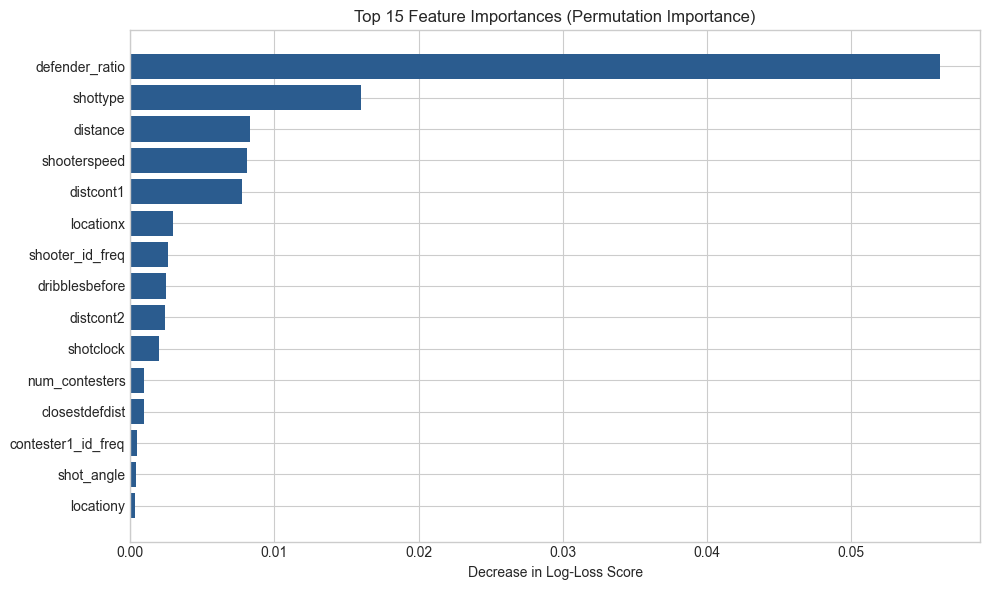

In [40]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

result = permutation_importance(model, X_va.iloc[:5000], y_val.iloc[:5000], scoring='neg_log_loss', n_repeats=5, random_state=42)

imp_df = pd.DataFrame({
    'feature': features,
    'importance': result.importances_mean
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(imp_df['feature'][:15][::-1], imp_df['importance'][:15][::-1], color='#2b5c8f')
plt.xlabel('Decrease in Log-Loss Score')
plt.title('Top 15 Feature Importances (Permutation Importance)')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()